## Climate indicator comparisons

In [1]:
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from scipy.stats import zscore, pearsonr
from scipy.stats import t as student_t
from statsmodels.tsa.stattools import acf
import matplotlib.lines as mlines

import warnings
warnings.filterwarnings("ignore")

IOPATH = '/ocean/rbeutel/MOAD/analysis-becca/Synthesis/data/CCS_obs.csv'

In [2]:
obs = pd.read_csv(IOPATH)
obs

,Unnamed: 0.1,Unnamed: 0,time,longitude (degrees_east),latitude (degrees_north),depth (m),pressure (dbar),temperature (degC),salinity (g kg-1),density (kg m-3),...,TA (uM),DIC (uM),source,current,location,[TA-DIC] (uM),year,month,NSdist,EWdist
0,0,0,1933-07-25 00:00:00+00:00,-126.76,49.34,1.0,1.008587,NaN,32.070847,NaN,...,NaN,NaN,ios bottle,shelf,shelf,NaN,1933,7,-158.177943,-0.0
1,1,1,1933-07-25 00:00:00+00:00,-126.76,49.34,2.0,2.017180,NaN,32.090943,NaN,...,NaN,NaN,ios bottle,shelf,shelf,NaN,1933,7,-158.177943,-0.0
2,2,2,1933-07-25 00:00:00+00:00,-126.76,49.34,4.0,4.034378,NaN,32.090906,NaN,...,NaN,NaN,ios bottle,shelf,shelf,NaN,1933,7,-158.177943,-0.0
3,3,3,1933-07-25 00:00:00+00:00,-126.76,49.34,6.0,6.051598,NaN,32.090870,NaN,...,NaN,NaN,ios bottle,shelf,shelf,NaN,1933,7,-158.177943,-0.0
4,4,4,1933-07-25 00:00:00+00:00,-126.76,49.34,10.0,10.086095,NaN,32.181305,NaN,...,NaN,NaN,ios bottle,shelf,shelf,NaN,1933,7,-158.177943,-0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1725713,1725713,1810291,2024-11-18 00:00:00+00:00,-124.95,44.38,0.0,0.000000,12.713836,32.386146,1024.310554,...,NaN,NaN,ooi,NaN,slope,NaN,2024,11,377.942065,NaN
1725714,1725714,1810292,2024-11-18 00:00:00+00:00,-124.94,44.36,0.0,0.000000,12.712860,32.386131,1024.310730,...,NaN,NaN,ooi,NaN,slope,NaN,2024,11,377.942065,NaN
1725715,1725715,1810293,2024-11-18 00:00:00+00:00,-124.57,46.99,0.0,0.000000,10.586080,32.728763,1024.962773,...,NaN,NaN,ooi,shelf,shelf,NaN,2024,11,133.256480,-0.0
1725716,1725716,1810294,2024-11-18 00:00:00+00:00,-124.56,46.99,0.0,0.000000,12.215222,32.245641,1024.296804,...,NaN,NaN,ooi,shelf,shelf,NaN,2024,11,133.256480,-0.0


In [3]:
pd.unique(obs['current'])

<ArrowStringArray>
['shelf', nan, 'CUC', 'CC']
Length: 4, dtype: str

In [4]:
# Setting up different currents
obs_shelf = obs[obs['current'] == 'shelf']
obs_cuc = obs[obs['current'] == 'CUC']
obs_cc = obs[obs['current'] == 'CC']

In [5]:
# make a 'dist' column of the distances we're actually going to use for each current
# for shelf and cuc its simply the NS dist

obs_cuc['dist'] = obs_cuc.NSdist
obs_shelf['dist'] = obs_shelf.NSdist

# for the CC its a bit more complicated
# first, just pick whatever line the point is closer to
abs_a = obs_cc.NSdist.abs()
abs_b = obs_cc.EWdist.abs()

obs_cc['dist'] = np.select(
    [
        abs_a < abs_b,       # a closer to zero
        abs_b < abs_a,       # b closer to zero
        abs_a.isna(),        # a NaN, take b
        abs_b.isna()         # b NaN, take a
    ],
    [
        obs_cc.NSdist,
        obs_cc.EWdist,
        obs_cc.EWdist,
        obs_cc.NSdist
    ],
    default=np.nan
)

# and then also default that anywhere that the NS dist is -ve, the EW distance should be taken
obs_cc.dist[obs_cc.NSdist < 0] = obs_cc.EWdist

### Where I got climate indicators from:

Originally from my research with Rich which can be found in /ocean/ghoeven/Atlas/Climatology2024

enso.csv (mei)
https://psl.noaa.gov/enso/mei/

enso (oni)
https://www.cpc.ncep.noaa.gov/data/indices/oni.ascii.txt

npgo.csv 
http://www.o3d.org/npgo/

pdo.csv
https://www.ncei.noaa.gov/access/monitoring/pdo/

bifurcation_index.csv
https://github.com/michaelmalick/bifurcation-index?utm_source=chatgpt.com

In [6]:
def add_time(df, year_col="year", month_col="month"):
    df = df.copy()
    df["day"] = 1
    df["time"] = pd.to_datetime(df[[year_col, month_col, "day"]])
    return df

def add_decimal_year(df, year_col="year", time_col="time"):
    df = df.copy()
    start_of_year = pd.to_datetime(df[year_col].astype(str) + "-01-01")
    end_of_year   = pd.to_datetime((df[year_col] + 1).astype(str) + "-01-01")
    df["decimal_yr"] = df[year_col] + (df[time_col] - start_of_year) / (end_of_year - start_of_year)
    return df

def add_running_mean_12m(value,time, *, center=True, min_periods=12):
    """
    12-month running mean on a monthly series.
    center=True -> centered window (recommended if you want a pure low-pass feel)
    min_periods=12 -> require a full 12 months for a value
    """
    s = pd.Series(np.array(value), index=pd.to_datetime(time)).sort_index()

    # original validity mask
    valid = ~s.isna()

    # fill gaps
    s_filled = s.asfreq("MS").interpolate("time", limit_direction="both")

    y = s_filled.rolling(window=12, center=True, min_periods=12).mean(engine="cython").to_numpy(copy=True) # added cython to make sure pandas doesn;t go to bottleneck

    # restore original NaN mask (prevents n increasing)
    y[~valid] = np.nan

    return y


# -------------------------
# ENSO (wide -> long -> monthly rm12)
# -------------------------
enso = pd.read_csv(
    "/ocean/rbeutel/MOAD/analysis-becca/Synthesis/data/enso1979.csv",
    names=["year"] + [str(x + 1) for x in range(12)]
)

enso = enso.melt(id_vars="year", var_name="month", value_name="index")
enso["month"] = enso["month"].astype(int)
enso = enso.sort_values(["year", "month"]).reset_index(drop=True)

enso = add_time(enso)
enso = add_decimal_year(enso)
enso["index_rm12"] = add_running_mean_12m(enso['index'],enso['time'])


# -------------------------
# ONI (already long -> monthly rm12)
# -------------------------
df = xr.open_dataset("/ocean/rbeutel/MOAD/analysis-becca/Synthesis/data/oni.nc")
oni = pd.DataFrame()
oni['year'] = df.time.dt.year.to_numpy()
oni['month'] = df.time.dt.month.to_numpy()
oni['time'] = df.time.to_numpy()
oni = add_decimal_year(oni)
oni['index'] = df.value.to_numpy()
oni["index_rm12"] = add_running_mean_12m(oni['index'],oni['time'])

# -------------------------
# NPGO (already long -> monthly rm12)
# -------------------------
npgo = pd.read_csv(
    "/ocean/rbeutel/MOAD/analysis-becca/Synthesis/data/npgo1950.csv",
    names=["year", "month", "index"]
)

npgo["month"] = npgo["month"].astype(int)
npgo = npgo.sort_values(["year", "month"]).reset_index(drop=True)

npgo = add_time(npgo)
npgo = add_decimal_year(npgo)
npgo["index_rm12"] = add_running_mean_12m(npgo['index'],npgo['time'])


# -------------------------
# PDO (wide -> long -> monthly rm12)
# -------------------------
pdo = pd.read_csv(
    "/ocean/rbeutel/MOAD/analysis-becca/Synthesis/data/pdo1854.csv",
    names=["year"] + [str(x + 1) for x in range(12)]
)

pdo = pdo.melt(id_vars="year", var_name="month", value_name="index")
pdo["month"] = pdo["month"].astype(int)
pdo = pdo.sort_values(["year", "month"]).reset_index(drop=True)

pdo = add_time(pdo)
pdo = add_decimal_year(pdo)
pdo["index_rm12"] = add_running_mean_12m(pdo['index'],pdo['time'])

# ------
# BI
# ------
df = pd.read_csv(
    "/ocean/rbeutel/MOAD/analysis-becca/Synthesis/data/bifurcation_index.csv",
    header=11,names=["year","index"],
)
bi = pd.DataFrame()
bi['year'] = np.repeat(df.year,12)
bi['month'] = np.tile(np.arange(1,13),len(df.year))
bi['day'] = 1
bi['index_rm12'] = np.repeat(df['index'],12)
bi['time'] = pd.to_datetime(bi[['year', 'month', 'day']])

start_of_year = pd.to_datetime(bi['year'].astype(str) + "-01-01")
end_of_year = pd.to_datetime((bi['year'] + 1).astype(str) + "-01-01")
bi['decimal_yr'] = bi['year'] + (
    (bi['time'] - start_of_year) / 
    (end_of_year - start_of_year)
)


In [7]:
oni

,year,month,time,decimal_yr,index,index_rm12
0,1950,1,1950-01-01,1950.000000,-1.53,NaN
1,1950,2,1950-02-01,1950.084932,-1.34,NaN
2,1950,3,1950-03-01,1950.161644,-1.16,NaN
3,1950,4,1950-04-01,1950.246575,-1.18,NaN
4,1950,5,1950-05-01,1950.328767,-1.07,NaN
...,...,...,...,...,...,...
913,2026,2,2026-02-01,2026.084932,-0.14,NaN
914,2026,3,2026-03-01,2026.161644,0.13,NaN
915,2026,4,2026-04-01,2026.246575,0.51,NaN
916,2026,5,2026-05-01,2026.328767,0.98,NaN


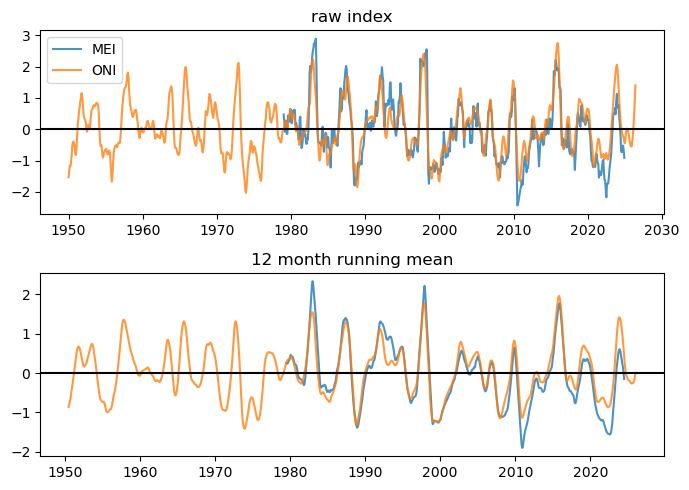

In [8]:
# comparison of oni and mei index for ENSO
fig, ax = plt.subplots(2,1,figsize=[7,5])

ax[0].plot(enso.time,enso['index'],alpha=0.8,label='MEI')
ax[0].plot(oni.time,oni['index'],alpha=0.8,label='ONI')
ax[0].axhline(c='k')
ax[0].legend()
ax[0].set_title('raw index')

ax[1].plot(enso.time,enso.index_rm12,alpha=0.8)
ax[1].plot(oni.time,oni.index_rm12,alpha=0.8)
ax[1].axhline(c='k')
ax[1].set_title('12 month running mean')

plt.tight_layout()

## Functions

In [9]:

def interpolation_monthly(
    obs_used, dist_edges, variable_str, *,
    usedist=False,
    depth_step=5.0, depth_bin=1.0,
    min_coverage=0.9, max_vertical_gap=50.0,
    min_depth_range=30.0, min_obs_per_month=3,
    depth_range=None
):
    """
    Interpolate mean profiles separately for each region/year/month.

    A single common depth interval is used for all regions and months.
    No extrapolation is permitted.

    If depth_range=(zmin, zmax) is supplied, use that interval
    instead of selecting it from sampling coverage.
    """
    horizontal = 'dist' if usedist else 'latitude (degrees_north)'

    cols = [horizontal, 'year', 'month', 'depth (m)', variable_str]
    s = _ensure_numeric(obs_used, cols)
    s = s.dropna(subset=cols).copy()

    if not 0 < min_coverage <= 1:
        raise ValueError("min_coverage must be between 0 and 1.")
    if depth_step <= 0 or depth_bin <= 0:
        raise ValueError("Depth intervals must be positive.")
    if max_vertical_gap is not None and max_vertical_gap <= 0:
        raise ValueError("max_vertical_gap must be positive.")

    output_cols = [
        'region', 'year', 'month', 'interpolated', 'mean',
        'n', 'n_depth', 'zmin_obs', 'zmax_obs', 'max_gap'
    ]

    def empty_result(z=None):
        out = pd.DataFrame(columns=output_cols)
        out.attrs['z_common'] = np.array([]) if z is None else z
        out.attrs['depth_range'] = (
            (np.nan, np.nan) if z is None else (z[0], z[-1])
        )
        return out

    s = s[
        s['month'].between(1, 12) &
        (s['month'] == np.floor(s['month'])) &
        (s['year'] == np.floor(s['year']))
    ].copy()

    s['region'] = pd.cut(
        s[horizontal],
        bins=dist_edges,
        right=False,
        include_lowest=True,
        labels=False
    )

    s = s.dropna(subset=['region'])

    if s.empty:
        return empty_result()

    s['region'] = s['region'].astype(int)
    s['year'] = s['year'].astype(int)
    s['month'] = s['month'].astype(int)
    s['z_bin'] = (
        np.round(s['depth (m)'] / depth_bin) * depth_bin
    )

    # ----------------------------------------------------------
    # 1. Construct monthly profiles for each region
    # ----------------------------------------------------------
    profiles = {}
    coverage_records = []

    for key, group in s.groupby(
        ['region', 'year', 'month'], sort=True
    ):
        n = len(group)

        if n < min_obs_per_month:
            continue

        profile = (
            group.groupby('z_bin')[variable_str]
            .mean()
            .sort_index()
        )

        if len(profile) < 2:
            continue

        z_obs = profile.index.to_numpy(dtype=float)
        v_obs = profile.to_numpy(dtype=float)

        profiles[key] = (z_obs, v_obs, n)

        coverage_records.append({
            'region': key[0],
            'year': key[1],
            'month': key[2],
            'n': n,
            'n_depth': len(z_obs),
            'zmin': z_obs.min(),
            'zmax': z_obs.max(),
            'max_gap': np.diff(z_obs).max()
        })

    if not profiles:
        print(f"{variable_str}: No eligible monthly profiles.")
        return empty_result()

    coverage = pd.DataFrame(coverage_records)

    # ----------------------------------------------------------
    # 2. Select common depth interval
    # ----------------------------------------------------------
    if depth_range is not None:
        zmin_requested, zmax_requested = map(float, depth_range)

        if zmax_requested - zmin_requested < min_depth_range:
            raise ValueError("Requested depth interval is too narrow.")

        n_steps = int(np.ceil(
            (zmax_requested - zmin_requested) / depth_step
        ))

        z_common = np.linspace(
            zmin_requested, zmax_requested, n_steps + 1
        )

    else:
        z_grid = np.arange(
            np.ceil(coverage['zmin'].min() / depth_step) * depth_step,
            np.floor(coverage['zmax'].max() / depth_step) * depth_step
            + depth_step * 0.5,
            depth_step
        )

        if len(z_grid) < 2:
            return empty_result()

        zlo = coverage['zmin'].to_numpy()
        zhi = coverage['zmax'].to_numpy()

        depth_covered = (
            (z_grid[:, None] >= zlo[None, :]) &
            (z_grid[:, None] <= zhi[None, :])
        )

        coverage_fraction = depth_covered.mean(axis=1)
        sufficient = coverage_fraction >= min_coverage

        changes = np.diff(
            np.r_[False, sufficient, False].astype(int)
        )

        starts = np.where(changes == 1)[0]
        ends = np.where(changes == -1)[0] - 1

        candidates = [
            (
                z_grid[e] - z_grid[b],
                coverage_fraction[b:e+1].mean(),
                b, e
            )
            for b, e in zip(starts, ends)
            if z_grid[e] - z_grid[b] >= min_depth_range
        ]

        if not candidates:
            print(
                f"{variable_str}: No depth interval satisfies "
                "the coverage criteria."
            )
            return empty_result()

        _, _, start, end = max(candidates)
        z_common = z_grid[start:end+1]

    zmin, zmax = z_common[0], z_common[-1]

    print(
        f"{variable_str}: common depth range "
        f"{zmin:.0f}–{zmax:.0f} m"
    )

    # ----------------------------------------------------------
    # 3. Interpolate qualifying monthly profiles
    # ----------------------------------------------------------
    records = []

    for (region, year, month), (z_obs, v_obs, n) in profiles.items():

        # Exclude profiles requiring extrapolation.
        if z_obs.min() > zmin or z_obs.max() < zmax:
            continue

        # Check gaps intersecting the selected depth range.
        gaps = np.diff(z_obs)
        intersects = (
            (z_obs[:-1] < zmax) &
            (z_obs[1:] > zmin)
        )

        if max_vertical_gap is not None:
            if np.any(gaps[intersects] > max_vertical_gap):
                continue

        interpolated = np.interp(z_common, z_obs, v_obs)

        if not np.all(np.isfinite(interpolated)):
            continue

        depth_mean = (
            np.trapezoid(interpolated, z_common) /
            (zmax - zmin)
        )

        records.append({
            'region': region,
            'year': year,
            'month': month,
            'interpolated': interpolated,
            'mean': depth_mean,
            'n': n,
            'n_depth': len(z_obs),
            'zmin_obs': z_obs.min(),
            'zmax_obs': z_obs.max(),
            'max_gap': gaps.max()
        })

    result = pd.DataFrame(records, columns=output_cols)
    result = result.sort_values(
        ['region', 'year', 'month']
    ).reset_index(drop=True)

    result.attrs['z_common'] = z_common
    result.attrs['depth_range'] = (zmin, zmax)

    print(
        f"Retained {len(result)} of {len(profiles)} "
        f"eligible monthly profiles "
        f"({100 * len(result) / len(profiles):.1f}%)."
    )

    return result


In [10]:
# ---------- helpers ----------
def _ensure_numeric(df, cols):
    out = df.copy()
    for c in cols:
        out[c] = pd.to_numeric(out[c], errors="coerce")
    return out

def decimal_year_monthstart_to_datetime(t_month):
    # get t_month into a date format that the filtering can handle
    t = np.asarray(t_month, float)
    years = np.floor(t).astype(int)
    months = (np.round((t - years) * 12).astype(int) + 1).clip(1, 12)
    return pd.to_datetime(
        {"year": years, "month": months, "day": np.ones_like(years)}
    )

def detrend_linear(s: pd.Series) -> pd.Series:
    """
    Remove a linear trend from a monthly series.
    Returns residuals with same index.
    """
    s = s.dropna().sort_index()
    if len(s) < 3:
        return s * np.nan

    x = np.arange(len(s), dtype=float)
    y = s.to_numpy(dtype=float)
    m, b = np.polyfit(x, y, 1)
    return pd.Series(y - (m*x + b), index=s.index)

# ---------- statistics ----------
def ACF_lag(value,time,*,runningmean=True,useconf=True):
    # calculate the autocorrelation timescale
    # value as array, time as df series

    if runningmean==True:
        value = add_running_mean_12m(value,time)
    s = pd.Series(value, index=time).sort_index().dropna()
    s = detrend_linear(s) 

    # compute ACF
    max_lag_months = 150
    rho = acf(s, nlags=max_lag_months, fft=True)
    lags = np.arange(max_lag_months+1)

    if useconf==True:
        # approximate 95% confidence interval for white noise
        conf = 1.96 / np.sqrt(len(s))
    else:
        conf=0

    # ---- first lag where ACF drops below +conf ----
    below = np.where(rho[:] <= conf)[0]  # indices in rho[1:]
    if below.size == 0:
        k_cross = np.nan
    else:
        k_cross = int(below[0])-1
    
    return k_cross

def _calc_stats_dof(mean_anom, df2, t_month, *, lag_months=0,
                    L_anom_months=np.nan, L_df2_months=np.nan):
    # p-value uses effective DOF.

    df2_series = pd.Series(df2['index_rm12'].values, index=df2['decimal_yr'])

    anom_series = pd.Series(mean_anom, index=t_month)
    anom_series = pd.Series(anom_series.values, index=anom_series.index + (lag_months / 12.0))

    df2_aligned = df2_series.reindex(anom_series.index, method='nearest', tolerance=1/52)

    mask = ~df2_aligned.isna() & ~anom_series.isna()
    x = anom_series[mask].values
    y = df2_aligned[mask].values

    out = {}
    out['n'] = int(mask.sum())
    if out['n'] > 2:
        out["r"] = pearsonr(x, y).statistic

        # choose conservative decorrelation lag
        out["L_used"] = np.nanmax([L_anom_months, L_df2_months])

        # if not np.isfinite(L_used) or L_used <= 0:
        #     return out

        out["neff"] = out['n'] / out["L_used"]

        out["pvalue"] = _pvalue_from_r_neff(out["r"], out["neff"])
    else: 
        out['r'] = np.nan
        out['pvalue'] = np.nan
        out["L_used"] = np.nan
        out["neff"] = np.nan

    return out

def find_best_lag_dof(mean_anom, t_month, df2,
                       L_anom_months, L_df2_months,
                       max_lag_months=6):
    r_by_lag, p_by_lag, n_by_lag = [], [], []
    neff_by_lag = []
    L_used_by_lag = []

    for k in range(int(max_lag_months) + 1):
        stats = _calc_stats_dof(
            mean_anom, df2, t_month,
            lag_months=k,
            L_anom_months=L_anom_months,
            L_df2_months=L_df2_months
        )
        r_by_lag.append(stats["r"])
        p_by_lag.append(stats["pvalue"])
        n_by_lag.append(stats["n"])
        neff_by_lag.append(stats["neff"])
        L_used_by_lag.append(stats["L_used"])

    r_arr = np.asarray(r_by_lag, float)
    if np.all(np.isnan(r_arr)): # if there is no correlation (no data) then just give this message:
        return {"best_lag_months": np.nan, "r": np.nan, "pvalue": np.nan, "n": 0,
                "neff": np.nan, "L_used": np.nan}

    kbest = int(np.nanargmax(np.abs(r_arr)))
    return {
        "best_lag_months": kbest,
        "r": r_by_lag[kbest],
        "pvalue": p_by_lag[kbest],
        "n": n_by_lag[kbest],
        "neff": neff_by_lag[kbest],
        "L_used": L_used_by_lag[kbest],
    }

def _pvalue_from_r_neff(r, neff):
    """
    Two-sided p-value for Pearson r using effective sample size neff.
    Returns a scalar p-value (float).
    """
    if not np.isfinite(r) or not np.isfinite(neff):
        return np.nan

    dof = neff - 2
    if dof <= 0:
        return np.nan

    r = np.clip(r, -0.999999, 0.999999)
    tstat = r * np.sqrt(dof / (1 - r**2))
    p = 2 * (1 - student_t.cdf(np.abs(tstat), dof))
    return p

def plot_panel(ax, mean_anom, df2, t_month,L_anom_months, L_df2_months,max_lag_months=6,colour='k',xloc=0,yloc=0.82):
    best = find_best_lag_dof(mean_anom, t_month, df2,
                       L_anom_months, L_df2_months, max_lag_months=max_lag_months)

    statstext = (f"Lag = {best['best_lag_months']} mo, n = {best['n']}\n"
                 f"r = {best['r']:.2f}  (p = {best['pvalue']:.3f}), auto={best['L_used']:.2f}")

    props = dict(boxstyle='round', facecolor='w',edgecolor=colour, alpha=0.7)
    c = ax.text(xloc, yloc, statstext, bbox=props, transform=ax.transAxes, fontsize=9)
    return c

# ---------- monthly lat-binned means ----------

def avg_profile_12months_dist(
    obs_used, dist_edges, variable_str,
    return_counts=False, usedist=False, *,
    do_interp=True, interpolated=None, **interp_kwargs
):
    nbins = len(dist_edges) - 1
    mean_arr = np.full((12, nbins), np.nan)
    cnt_arr = np.zeros((12, nbins), dtype=int)

    # ----------------------------------------------------------
    # Original method: no interpolation
    # ----------------------------------------------------------
    if not do_interp:
        horizontal = 'dist' if usedist else 'latitude (degrees_north)'

        s = _ensure_numeric(
            obs_used, [variable_str, horizontal, 'month']
        )

        s = s.dropna(
            subset=[variable_str, horizontal, 'month']
        ).copy()

        s = s[
            s['month'].between(1, 12) &
            (s['month'] == np.floor(s['month']))
        ].copy()

        s['_zbin'] = pd.cut(
            s[horizontal],
            bins=dist_edges,
            right=False,
            include_lowest=True,
            labels=False
        )

        s = s.dropna(subset=['_zbin'])
        s['_month'] = s['month'].astype(int)

        g = s.groupby(
            ['_month', '_zbin']
        )[variable_str].agg(['mean', 'count'])

        for (month, region), row in g.iterrows():
            mean_arr[int(month)-1, int(region)] = row['mean']
            cnt_arr[int(month)-1, int(region)] = row['count']

    # ----------------------------------------------------------
    # New method: depth-standardized monthly profiles
    # ----------------------------------------------------------
    else:
        if interpolated is None:
            interpolated = interpolation_monthly(
                obs_used, dist_edges, variable_str,
                usedist=usedist, **interp_kwargs
            )

        if not interpolated.empty:
            g = (
                interpolated.groupby(['month', 'region'])['mean']
                .agg(['mean', 'count'])
            )

            for (month, region), row in g.iterrows():
                mean_arr[int(month)-1, int(region)] = row['mean']
                cnt_arr[int(month)-1, int(region)] = row['count']

    return (mean_arr, cnt_arr) if return_counts else mean_arr





def contour_prep_dist_monthly(
    obs_used, start_yr, end_yr, dist_edges,
    variable_str, base_period=None,
    min_samples_per_cell=3, usedist=False, *,
    do_interp=True,
    depth_step=5.0, depth_bin=10.0,
    min_coverage=0.9, max_vertical_gap=50.0,
    min_depth_range=30.0, depth_range=None,
    return_interpolated=False
):
    years = np.arange(int(start_yr), int(end_yr) + 1)
    nyears = len(years)
    nbins = len(dist_edges) - 1

    if nyears == 0:
        raise ValueError("end_yr must be >= start_yr.")

    # ----------------------------------------------------------
    # 1. Original method: no depth interpolation
    # ----------------------------------------------------------
    if not do_interp:

        # Climatology base period
        if base_period is not None:
            by0, by1 = base_period
            clim_obs = obs_used[
                (obs_used['year'] >= by0) &
                (obs_used['year'] <= by1)
            ]
        else:
            clim_obs = obs_used

        # Original pooled-observation monthly climatology
        clim_mean = avg_profile_12months_dist(
            clim_obs, dist_edges, variable_str,
            usedist=usedist, do_interp=False
        )

        yr_month_means = []
        yr_month_counts = []

        for yr in years:
            m12, c12 = avg_profile_12months_dist(
                obs_used[obs_used['year'] == yr],
                dist_edges, variable_str,
                return_counts=True,
                usedist=usedist,
                do_interp=False
            )

            yr_month_means.append(m12)
            yr_month_counts.append(c12)

        yr_means = np.vstack(yr_month_means)
        yr_counts = np.vstack(yr_month_counts)

        monthly = None

    # ----------------------------------------------------------
    # 2. New method: depth-standardized monthly profiles
    # ----------------------------------------------------------
    else:

        # Include both analysis and climatology periods
        if base_period is None:
            source = obs_used
        else:
            by0, by1 = base_period
            ymin = min(start_yr, by0)
            ymax = max(end_yr, by1)

            source = obs_used[
                (obs_used['year'] >= ymin) &
                (obs_used['year'] <= ymax)
            ]

        # Interpolate all monthly profiles using one common
        # depth interval across all regions and years.
        monthly = interpolation_monthly(
            source,
            dist_edges,
            variable_str,
            usedist=usedist,
            depth_step=depth_step,
            depth_bin=depth_bin,
            min_coverage=min_coverage,
            max_vertical_gap=max_vertical_gap,
            min_depth_range=min_depth_range,
            min_obs_per_month=min_samples_per_cell,
            depth_range=depth_range
        )

        # Select climatology period
        if base_period is not None:
            by0, by1 = base_period
            clim_data = monthly[
                monthly['year'].between(by0, by1)
            ]
        else:
            clim_data = monthly

        # Climatology of depth-standardized monthly means
        clim_mean = avg_profile_12months_dist(
            source, dist_edges, variable_str,
            usedist=usedist,
            do_interp=True,
            interpolated=clim_data
        )

        # Populate monthly time series
        yr_means = np.full(
            (nyears * 12, nbins), np.nan
        )
        yr_counts = np.zeros(
            (nyears * 12, nbins), dtype=int
        )

        if not monthly.empty:
            selected = monthly[
                monthly['year'].between(start_yr, end_yr)
            ]

            for row in selected.itertuples(index=False):
                t_idx = (
                    (int(row.year) - int(start_yr)) * 12 +
                    (int(row.month) - 1)
                )

                region = int(row.region)

                yr_means[t_idx, region] = row.mean
                yr_counts[t_idx, region] = row.n

    # ----------------------------------------------------------
    # 3. Calculate monthly anomalies
    # ----------------------------------------------------------
    clim_tiled = np.tile(clim_mean, (nyears, 1))
    anom = yr_means - clim_tiled

    # Require sufficient samples for each monthly estimate.
    anom[yr_counts < min_samples_per_cell] = np.nan

    # ----------------------------------------------------------
    # 4. Construct monthly time axis
    # ----------------------------------------------------------
    months = np.tile(np.arange(1, 13), nyears)
    years_rep = np.repeat(years, 12)

    t_month = years_rep + (months - 1) / 12.0

    if return_interpolated:
        return anom.T, t_month, monthly

    return anom.T, t_month



## Autocorrelation

MEI: first lag below conf = 12 months (conf=0.084)
MEI: first lag below 0 = 13 months
ONI: first lag below conf = 11 months (conf=0.065)
ONI: first lag below 0 = 12 months
PDO: first lag below conf = 68 months (conf=0.043)
PDO: first lag below 0 = 82 months
NPGO: first lag below conf = 44 months (conf=0.066)
NPGO: first lag below 0 = 49 months
BI: first lag below conf = 14 months (conf=0.074)
BI: first lag below 0 = 54 months


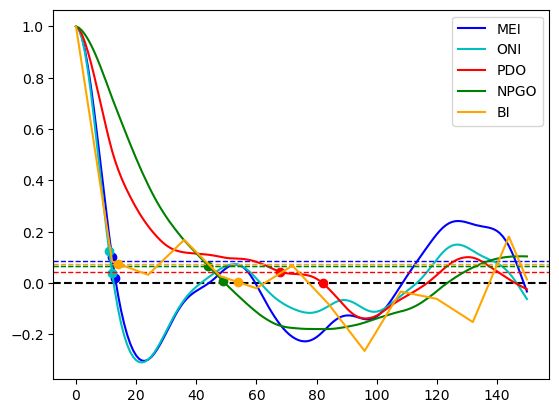

In [11]:
# autocorrelation of the different indices

names = ['MEI','ONI','PDO','NPGO','BI']
indices = [enso,oni,pdo,npgo,bi]
colours = ['b','c','r','g','orange']

# plot autocorrelation as a function of time
fig, ax = plt.subplots(1,1)
ax.axhline(0,color='k',ls='--')

for i in range(len(indices)):

        value = indices[i]['index_rm12'].values
        s = pd.Series(value, index=indices[i].time).sort_index().dropna()
        s = detrend_linear(s) 
        
        # compute ACF
        max_lag_months = 150
        rho = acf(s, nlags=max_lag_months, fft=True)
        lags = np.arange(max_lag_months+1)
        ax.plot(lags,rho,color=colours[i],label=names[i])

        # approximate 95% confidence interval for white noise
        conf = 1.96 / np.sqrt(len(s))
        ax.axhline(conf, color=colours[i],ls='--', lw=1)
        # ax.axhline(-conf, color=colours[i], ls='--', lw=1)

        # ---- first lag where ACF drops below +conf ----
        below = np.where(rho[:] <= conf)[0]  # indices in rho[1:]
        if below.size == 0:
                k_cross = np.nan
                print(f"{names[i]}: ACF does not drop below conf out to {nlags} months (conf={conf:.3f})")
        else:
                k_cross = int(below[0])-1 
                print(f"{names[i]}: first lag below conf = {k_cross} months (conf={conf:.3f})")

                # mark it on the plot
                ax.plot(k_cross, rho[k_cross], marker='o', color=colours[i])
        
        # ---- second lag where ACF drops below 0 ----
        below = np.where(rho[:] <= 0)[0] 
        if below.size == 0:
                k_cross = np.nan
                print(f"{names[i]}: ACF does not drop below 0 out to {nlags} months (conf={conf:.3f})")
        else:
                k_cross = int(below[0])-1
                print(f"{names[i]}: first lag below 0 = {k_cross} months")

                # mark it on the plot
                ax.plot(k_cross, rho[k_cross], marker='o', color=colours[i])
ax.legend()

In [12]:
# running mean already calculated for the indices
Lenso = ACF_lag(enso['index_rm12'].values,enso.time,runningmean=False)
Loni = ACF_lag(oni['index_rm12'].values,oni.time,runningmean=False)
Lpdo = ACF_lag(pdo['index_rm12'].values,pdo.time,runningmean=False)
Lnpgo = ACF_lag(npgo['index_rm12'].values,npgo.time,runningmean=False)
Lbi = ACF_lag(bi['index_rm12'].values,bi.time,runningmean=False)

## Tables

In [13]:
def tables(obs_used, dist_edges, *, base_period= (1991, 2020), min_samples_per_cell=3, usedist=False, do_interp=True):
# prints out correlation results for each of the variables and indices

    vars = ['temperature (degC)', 'salinity (g kg-1)','spice','DO (umol kg-1)','NO3 (uM)']

    for variable_str in vars:
        print(variable_str)
        start_yr = int(np.nanmin(obs_used.year[~np.isnan(obs_used[variable_str])]))
        end_yr   = int(np.nanmax(obs_used.year[~np.isnan(obs_used[variable_str])]))

        anom_array, t_month = contour_prep_dist_monthly(
            obs_used, start_yr, end_yr, dist_edges,
            variable_str, base_period=base_period, min_samples_per_cell=min_samples_per_cell, 
            usedist=usedist, do_interp=do_interp
        )
        time = decimal_year_monthstart_to_datetime(t_month)

        regions = ['Southern','Central','Northern']
        for i in range(len(regions)):

            L = ACF_lag(anom_array[i],time)

            print(regions[i])
            best = find_best_lag_dof(add_running_mean_12m(anom_array[i],time), t_month, enso, L,Lenso,max_lag_months=6)
            print(f"MEI & {best['r']:.2f} & {best['pvalue']:.3f} & {best['best_lag_months']} & {best['n']}")
            best = find_best_lag_dof(add_running_mean_12m(anom_array[i],time), t_month, oni, L,Loni,max_lag_months=6)
            print(f"ONI & {best['r']:.2f} & {best['pvalue']:.3f} & {best['best_lag_months']} & {best['n']}")
            best = find_best_lag_dof(add_running_mean_12m(anom_array[i],time), t_month, pdo,L,Lpdo, max_lag_months=6)
            print(f"PDO & {best['r']:.2f} & {best['pvalue']:.3f} & {best['best_lag_months']} & {best['n']}")
            best = find_best_lag_dof(add_running_mean_12m(anom_array[i],time), t_month, npgo,L,Lnpgo, max_lag_months=6)
            print(f"NPGO & {best['r']:.2f} & {best['pvalue']:.3f} & {best['best_lag_months']} & {best['n']}")
            best = find_best_lag_dof(add_running_mean_12m(anom_array[i],time), t_month, bi,L,Lbi, max_lag_months=6)
            print(f"BI & {best['r']:.2f} & {best['pvalue']:.3f} & {best['best_lag_months']} & {best['n']}")
            print("\n")

In [14]:
base_period = (1991, 2020)
obs_used = obs_shelf.copy()
dist_edges = [np.nanmin(obs_used['latitude (degrees_north)'])-0.1,34.45,40.44,np.nanmax(obs_used['latitude (degrees_north)'])+0.1]

tables(obs_used,dist_edges)

temperature (degC)
temperature (degC): common depth range 0–60 m
Retained 947 of 999 eligible monthly profiles (94.8%).
Southern
MEI & 0.63 & 0.006 & 0 & 210
ONI & 0.55 & 0.001 & 0 & 386
PDO & 0.44 & 0.399 & 2 & 386
NPGO & -0.38 & 0.315 & 0 & 386
BI & -0.27 & 0.265 & 4 & 260


Central
MEI & 0.69 & 0.014 & 0 & 164
ONI & 0.37 & 0.142 & 0 & 235
PDO & 0.50 & 0.577 & 0 & 235
NPGO & -0.28 & 0.624 & 6 & 235
BI & -0.10 & 0.746 & 6 & 187


Northern
MEI & 0.72 & 0.004 & 0 & 313
ONI & 0.66 & 0.010 & 0 & 318
PDO & 0.81 & 0.124 & 0 & 318
NPGO & -0.29 & 0.512 & 0 & 318
BI & -0.35 & 0.227 & 0 & 314


salinity (g kg-1)
salinity (g kg-1): common depth range 0–60 m
Retained 1105 of 1213 eligible monthly profiles (91.1%).
Southern
MEI & -0.39 & 0.155 & 5 & 210
ONI & 0.14 & 0.479 & 6 & 389
PDO & -0.22 & 0.690 & 0 & 389
NPGO & 0.08 & 0.843 & 6 & 389
BI & 0.27 & 0.275 & 6 & 261


Central
MEI & -0.60 & 0.025 & 1 & 164
ONI & -0.50 & 0.020 & 0 & 237
PDO & -0.43 & 0.641 & 1 & 237
NPGO & 0.26 & 0.646 & 6 & 237
B

In [15]:
base_period = (1991, 2020)
obs_used = obs_cuc.copy()
dist_edges = [np.nanmin(obs_used['latitude (degrees_north)'])-0.1,34.45,40.44,np.nanmax(obs_used['latitude (degrees_north)'])+0.1]

tables(obs_used,dist_edges,do_interp=False)

temperature (degC)
Southern
MEI & 0.06 & 0.807 & 5 & 226
ONI & 0.23 & 0.162 & 3 & 434
PDO & -0.09 & 0.862 & 0 & 441
NPGO & -0.16 & 0.669 & 0 & 431
BI & 0.16 & 0.498 & 6 & 291


Central
MEI & 0.04 & 0.902 & 0 & 155
ONI & 0.10 & 0.660 & 0 & 245
PDO & 0.30 & 0.720 & 1 & 255
NPGO & 0.05 & 0.926 & 0 & 245
BI & 0.09 & 0.759 & 0 & 181


Northern
MEI & 0.38 & 0.156 & 6 & 265
ONI & 0.32 & 0.225 & 6 & 276
PDO & 0.12 & 0.876 & 2 & 281
NPGO & -0.41 & 0.400 & 4 & 276
BI & 0.12 & 0.670 & 6 & 268


salinity (g kg-1)
Southern
MEI & 0.03 & 0.894 & 3 & 226
ONI & 0.21 & 0.189 & 3 & 434
PDO & -0.10 & 0.846 & 0 & 441
NPGO & -0.15 & 0.689 & 0 & 431
BI & 0.16 & 0.489 & 6 & 291


Central
MEI & -0.06 & 0.839 & 6 & 155
ONI & 0.08 & 0.726 & 0 & 245
PDO & 0.31 & 0.717 & 0 & 255
NPGO & 0.04 & 0.947 & 6 & 251
BI & 0.07 & 0.812 & 0 & 181


Northern
MEI & 0.27 & 0.421 & 6 & 265
ONI & 0.24 & 0.472 & 6 & 276
PDO & 0.08 & 0.916 & 1 & 281
NPGO & -0.41 & 0.406 & 2 & 276
BI & 0.03 & 0.920 & 6 & 268


spice
Southern
MEI & 0

Southern
MEI & -0.49 & 0.047 & 0 & 204
ONI & -0.15 & 0.509 & 0 & 226
PDO & -0.23 & 0.821 & 0 & 226
NPGO & 0.21 & 0.734 & 0 & 226
BI & 0.10 & 0.715 & 0 & 226


Central
MEI & -0.38 & 0.210 & 4 & 152
ONI & -0.24 & 0.394 & 4 & 164
PDO & -0.48 & 0.832 & 0 & 164
NPGO & 0.30 & 0.722 & 4 & 164
BI & 0.29 & 0.363 & 2 & 164


Northern
MEI & -0.35 & 0.309 & 0 & 126
ONI & -0.25 & 0.437 & 0 & 129
PDO & -0.28 & nan & 0 & 129
NPGO & -0.04 & 0.975 & 6 & 129
BI & 0.15 & 0.687 & 0 & 129




In [16]:
base_period = (1991, 2020)
obs_used = obs_cc.copy()
dist_edges = [np.nanmin(obs_used['latitude (degrees_north)'])-0.1,34.45,40.44,np.nanmax(obs_used['latitude (degrees_north)'])+0.1]

tables(obs_used,dist_edges)

temperature (degC)
temperature (degC): common depth range 0–140 m
Retained 724 of 819 eligible monthly profiles (88.4%).
Southern
MEI & 0.60 & 0.041 & 0 & 227
ONI & 0.45 & 0.032 & 0 & 425
PDO & 0.42 & 0.382 & 0 & 436
NPGO & -0.44 & 0.213 & 0 & 425
BI & -0.30 & 0.271 & 0 & 287


Central
MEI & 0.44 & 0.762 & 2 & 33
ONI & 0.14 & 0.732 & 0 & 93
PDO & 0.73 & nan & 0 & 99
NPGO & -0.07 & 0.988 & 6 & 97
BI & -0.56 & 0.456 & 0 & 54


Northern
MEI & 0.65 & 0.053 & 0 & 113
ONI & 0.45 & 0.148 & 0 & 130
PDO & 0.57 & 0.982 & 0 & 138
NPGO & -0.29 & 0.812 & 4 & 133
BI & -0.14 & 0.721 & 4 & 119


salinity (g kg-1)
salinity (g kg-1): common depth range 0–140 m
Retained 724 of 819 eligible monthly profiles (88.4%).
Southern
MEI & -0.21 & 0.655 & 5 & 227
ONI & -0.08 & 0.798 & 0 & 425
PDO & -0.07 & 0.887 & 0 & 436
NPGO & 0.05 & 0.889 & 6 & 431
BI & 0.10 & 0.806 & 6 & 290


Central
MEI & -0.11 & 0.942 & 0 & 33
ONI & -0.16 & 0.686 & 1 & 93
PDO & 0.06 & nan & 6 & 99
NPGO & 0.13 & 0.977 & 6 & 97
BI & 0.52 & 0.

In [17]:
base_period = (1991, 2020)
indice= bi

num_obs = 50
vars = ['temperature (degC)', 'salinity (g kg-1)','spice','DO (umol kg-1)','NO3 (uM)']
varmark = ['P','X','o','^','d']

dist_edges = [np.min(obs_cc.dist),0,800]
regions = ['NPC', 'Alongshore']

obs_used = obs_cc.copy()
for i in range(len(vars)):
    print(vars[i])

    start_yr = int(np.nanmin(obs_used.year[~np.isnan(obs_used[vars[i]])]))
    end_yr   = int(np.nanmax(obs_used.year[~np.isnan(obs_used[vars[i]])]))

    anom_array, t_month = contour_prep_dist_monthly(
        obs_used, start_yr, end_yr, dist_edges,
        vars[i], base_period=base_period, min_samples_per_cell=3,usedist=True
    )
    time = decimal_year_monthstart_to_datetime(t_month)

    for j in range(len(regions)):
        print(regions[j])
        L = ACF_lag(anom_array[j],time)

        best = find_best_lag_dof(add_running_mean_12m(anom_array[j],time), t_month, bi,L,Lbi, max_lag_months=6)
        print(f"BI & {best['r']:.2f} & {best['pvalue']:.3f} & {best['best_lag_months']} & {best['n']}")
    print("\n")

temperature (degC)
temperature (degC): common depth range 10–100 m
Retained 241 of 251 eligible monthly profiles (96.0%).
NPC
BI & -0.07 & 0.865 & 6 & 115
Alongshore
BI & -0.22 & 0.638 & 4 & 98


salinity (g kg-1)


salinity (g kg-1): common depth range 10–100 m
Retained 241 of 251 eligible monthly profiles (96.0%).
NPC
BI & -0.48 & 0.220 & 0 & 115
Alongshore
BI & -0.12 & 0.806 & 0 & 98


spice
spice: common depth range 10–100 m
Retained 241 of 251 eligible monthly profiles (96.0%).
NPC
BI & -0.33 & 0.413 & 6 & 115
Alongshore
BI & -0.26 & 0.580 & 0 & 98


DO (umol kg-1)
DO (umol kg-1): common depth range 0–100 m
Retained 201 of 223 eligible monthly profiles (90.1%).
NPC
BI & 0.04 & 0.933 & 6 & 98
Alongshore
BI & -0.10 & 0.866 & 2 & 78


NO3 (uM)
NO3 (uM): common depth range 0–100 m
Retained 121 of 136 eligible monthly profiles (89.0%).
NPC
BI & 0.16 & 0.735 & 6 & 100
Alongshore
BI & -0.16 & nan & 5 & 19




## Summary Plots

In [18]:
def summary_plot(ax, obs_used, indice, Lindice, dist_edges, *, base_period= (1991, 2020), min_samples_per_cell=3,p=0.1,do_interp=True):

    vars = ['temperature (degC)', 'salinity (g kg-1)','spice','DO (umol kg-1)','NO3 (uM)']
    varmark = ['P','X','o','^','d']
    sig_count = 0

    for i in range(len(vars)):
        start_yr = int(np.nanmin(obs_used.year[~np.isnan(obs_used[vars[i]])]))
        end_yr   = int(np.nanmax(obs_used.year[~np.isnan(obs_used[vars[i]])]))

        anom_array, t_month = contour_prep_dist_monthly(
            obs_used, start_yr, end_yr, dist_edges,
            vars[i], base_period=base_period, min_samples_per_cell=min_samples_per_cell,do_interp=do_interp
        )
        time = decimal_year_monthstart_to_datetime(t_month)

        L = ACF_lag(anom_array[0],time)
        best = find_best_lag_dof(add_running_mean_12m(anom_array[0],time), t_month, indice,L,Lindice, max_lag_months=6)
        if best['pvalue'] <= p and best['n'] >100:
            ax.scatter(best['best_lag_months'],best['r'],marker=varmark[i],s=50,color='#BB5566',alpha=0.7)
            sig_count+=1
        
        L = ACF_lag(anom_array[1],time)
        best = find_best_lag_dof(add_running_mean_12m(anom_array[1],time), t_month, indice,L,Lindice, max_lag_months=6)
        if best['pvalue'] <= p and best['n'] >100:
            ax.scatter(best['best_lag_months'],best['r'],marker=varmark[i],s=50,color='#DDAA33',alpha=0.7)
            sig_count+=1
        
        L = ACF_lag(anom_array[2],time)
        best = find_best_lag_dof(add_running_mean_12m(anom_array[2],time), t_month, indice,L,Lindice, max_lag_months=6)
        if best['pvalue'] <= p and best['n'] >100:
            ax.scatter(best['best_lag_months'],best['r'],marker=varmark[i],s=50,color='#004488',alpha=0.5)
            sig_count+=1

    return sig_count


temperature (degC): common depth range 0–60 m
Retained 947 of 999 eligible monthly profiles (94.8%).
salinity (g kg-1): common depth range 0–60 m
Retained 1105 of 1213 eligible monthly profiles (91.1%).
spice: common depth range 0–60 m
Retained 947 of 999 eligible monthly profiles (94.8%).
DO (umol kg-1): common depth range 0–60 m
Retained 824 of 898 eligible monthly profiles (91.8%).
NO3 (uM): common depth range 0–60 m
Retained 498 of 582 eligible monthly profiles (85.6%).
temperature (degC): common depth range 0–140 m
Retained 724 of 819 eligible monthly profiles (88.4%).
salinity (g kg-1): common depth range 0–140 m
Retained 724 of 819 eligible monthly profiles (88.4%).
spice: common depth range 0–140 m
Retained 724 of 819 eligible monthly profiles (88.4%).
DO (umol kg-1): common depth range 0–130 m
Retained 675 of 757 eligible monthly profiles (89.2%).
NO3 (uM): common depth range 0–120 m
Retained 392 of 426 eligible monthly profiles (92.0%).
28.888888888888886


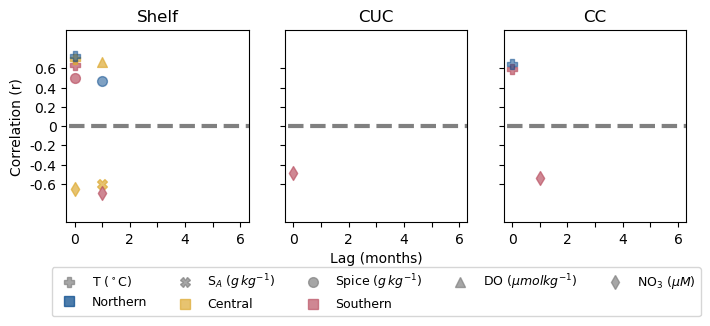

In [19]:
# ENSO - MEI
indice= enso
Lindice = Lenso

fig, axs = plt.subplots(1,3,figsize=[8,2.5])

for ax in axs:
    ax.set_ylim([-1,1])
    ax.set_xlim([-0.3,6.3])
    ax.plot([-1,7],[0,0],color='grey',ls='dashed',lw=3)
    ax.set_yticks([-0.6,-0.4,-0.2,0,0.2,0.4,0.6])
    ax.set_yticklabels([])
    ax.set_xticks([0,1,2,3,4,5,6])
    ax.set_xticklabels(['0','','2','','4','','6'])
axs[0].set_yticklabels([-0.6,-0.4,-0.2,0,0.2,0.4,0.6])
axs[0].set_ylabel('Correlation (r)')
axs[1].set_xlabel('Lag (months)')
axs[0].set_title('Shelf')
axs[1].set_title('CUC')
axs[2].set_title('CC')

sig_count = 0
obs_used = obs_shelf.copy()
dist_edges = [np.nanmin(obs_used['latitude (degrees_north)'])-0.1,34.45,40.44,np.nanmax(obs_used['latitude (degrees_north)'])+0.1]
n = summary_plot(axs[0], obs_used, indice, Lindice,dist_edges)
sig_count += n

obs_used = obs_cuc.copy()
dist_edges = [np.nanmin(obs_used['latitude (degrees_north)'])-0.1,34.45,40.44,np.nanmax(obs_used['latitude (degrees_north)'])+0.1]
n = summary_plot(axs[1], obs_used, indice, Lindice,dist_edges,do_interp=False)
sig_count += n

obs_used = obs_cc.copy()
dist_edges = [np.nanmin(obs_used['latitude (degrees_north)'])-0.1,34.45,40.44,np.nanmax(obs_used['latitude (degrees_north)'])+0.1]
n = summary_plot(axs[2], obs_used, indice, Lindice,dist_edges)
sig_count += n

print(sig_count/(5*3*3)*100) # percentage of tested relationships that are significant

# # build legend handles    
legend_handles = []
inlegend = ['T ($^\circ$C)', 'Northern', 'S$_A$ ($g \,kg^{-1}$)', 'Central', 'Spice ($g \,kg^{-1}$)','Southern','DO ($\mu mol kg^{-1}$)','NO$_3$ ($\mu M$)',]
colours = ['grey','#004488','grey','#DDAA33','grey','#BB5566','grey','grey']
markers = ['P','s','X','s','o','s','^','d']
for i in range(len(inlegend)):
    legend_handles.append(mlines.Line2D([], [], 
                          marker=markers[i], linestyle='None',markersize=7,
                          markeredgecolor=colours[i], markerfacecolor=colours[i],alpha=0.7,
                          label=inlegend[i]))
# Add a figure-wide legend below the subplots
axs[1].legend(handles=legend_handles, loc='upper center', ncol=5, bbox_to_anchor=(0.5, -0.2), frameon=True,fontsize=9)

plt.savefig('/ocean/rbeutel/MOAD/analysis-becca/Synthesis/output/enso.png', bbox_inches='tight')

# shelf nCCS and sCCS temperature, cCCS salinity, and cCCS nitrate correlation significant on p=0.05
# CC sCCS temperature significant on p=0.05

temperature (degC): common depth range 0–60 m
Retained 947 of 999 eligible monthly profiles (94.8%).
salinity (g kg-1): common depth range 0–60 m
Retained 1105 of 1213 eligible monthly profiles (91.1%).
spice: common depth range 0–60 m
Retained 947 of 999 eligible monthly profiles (94.8%).
DO (umol kg-1): common depth range 0–60 m
Retained 824 of 898 eligible monthly profiles (91.8%).
NO3 (uM): common depth range 0–60 m
Retained 498 of 582 eligible monthly profiles (85.6%).
temperature (degC): common depth range 0–140 m
Retained 724 of 819 eligible monthly profiles (88.4%).
salinity (g kg-1): common depth range 0–140 m
Retained 724 of 819 eligible monthly profiles (88.4%).
spice: common depth range 0–140 m
Retained 724 of 819 eligible monthly profiles (88.4%).
DO (umol kg-1): common depth range 0–130 m
Retained 675 of 757 eligible monthly profiles (89.2%).
NO3 (uM): common depth range 0–120 m
Retained 392 of 426 eligible monthly profiles (92.0%).
20.0


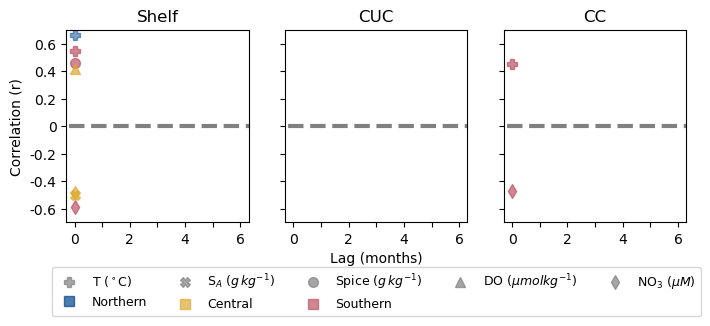

In [20]:
# ENSO - ONI
indice= oni
Lindice = Loni

fig, axs = plt.subplots(1,3,figsize=[8,2.5])

for ax in axs:
    ax.set_ylim([-0.7,0.7])
    ax.set_xlim([-0.3,6.3])
    ax.plot([-1,7],[0,0],color='grey',ls='dashed',lw=3)
    ax.set_yticks([-0.6,-0.4,-0.2,0,0.2,0.4,0.6])
    ax.set_yticklabels([])
    ax.set_xticks([0,1,2,3,4,5,6])
    ax.set_xticklabels(['0','','2','','4','','6'])
axs[0].set_yticklabels([-0.6,-0.4,-0.2,0,0.2,0.4,0.6])
axs[0].set_ylabel('Correlation (r)')
axs[1].set_xlabel('Lag (months)')
axs[0].set_title('Shelf')
axs[1].set_title('CUC')
axs[2].set_title('CC')

sig_count = 0
obs_used = obs_shelf.copy()
dist_edges = [np.nanmin(obs_used['latitude (degrees_north)'])-0.1,34.45,40.44,np.nanmax(obs_used['latitude (degrees_north)'])+0.1]
n = summary_plot(axs[0], obs_used, indice, Lindice,dist_edges)
sig_count += n

obs_used = obs_cuc.copy()
dist_edges = [np.nanmin(obs_used['latitude (degrees_north)'])-0.1,34.45,40.44,np.nanmax(obs_used['latitude (degrees_north)'])+0.1]
n = summary_plot(axs[1], obs_used, indice, Lindice,dist_edges,do_interp=False)
sig_count += n

obs_used = obs_cc.copy()
dist_edges = [np.nanmin(obs_used['latitude (degrees_north)'])-0.1,34.45,40.44,np.nanmax(obs_used['latitude (degrees_north)'])+0.1]
n = summary_plot(axs[2], obs_used, indice, Lindice,dist_edges)
sig_count += n

print(sig_count/(5*3*3)*100) # percentage of tested relationships that are significant

# # build legend handles    
legend_handles = []
inlegend = ['T ($^\circ$C)', 'Northern', 'S$_A$ ($g \,kg^{-1}$)', 'Central', 'Spice ($g \,kg^{-1}$)','Southern','DO ($\mu mol kg^{-1}$)','NO$_3$ ($\mu M$)',]
colours = ['grey','#004488','grey','#DDAA33','grey','#BB5566','grey','grey']
markers = ['P','s','X','s','o','s','^','d']
for i in range(len(inlegend)):
    legend_handles.append(mlines.Line2D([], [], 
                          marker=markers[i], linestyle='None',markersize=7,
                          markeredgecolor=colours[i], markerfacecolor=colours[i],alpha=0.7,
                          label=inlegend[i]))
# Add a figure-wide legend below the subplots
axs[1].legend(handles=legend_handles, loc='upper center', ncol=5, bbox_to_anchor=(0.5, -0.2), frameon=True,fontsize=9)

plt.savefig('/ocean/rbeutel/MOAD/analysis-becca/Synthesis/output/oni.png', bbox_inches='tight')

# shelf nCCS and sCCS temperature, cCCS salinity, and cCCS nitrate correlation significant on p=0.05
# CC sCCS temperature significant on p=0.05

temperature (degC): common depth range 0–60 m
Retained 947 of 999 eligible monthly profiles (94.8%).
salinity (g kg-1): common depth range 0–60 m
Retained 1105 of 1213 eligible monthly profiles (91.1%).
spice: common depth range 0–60 m
Retained 947 of 999 eligible monthly profiles (94.8%).
DO (umol kg-1): common depth range 0–60 m
Retained 824 of 898 eligible monthly profiles (91.8%).
NO3 (uM): common depth range 0–60 m
Retained 498 of 582 eligible monthly profiles (85.6%).
temperature (degC): common depth range 0–140 m
Retained 724 of 819 eligible monthly profiles (88.4%).
salinity (g kg-1): common depth range 0–140 m
Retained 724 of 819 eligible monthly profiles (88.4%).
spice: common depth range 0–140 m
Retained 724 of 819 eligible monthly profiles (88.4%).
DO (umol kg-1): common depth range 0–130 m
Retained 675 of 757 eligible monthly profiles (89.2%).
NO3 (uM): common depth range 0–120 m
Retained 392 of 426 eligible monthly profiles (92.0%).
0.0


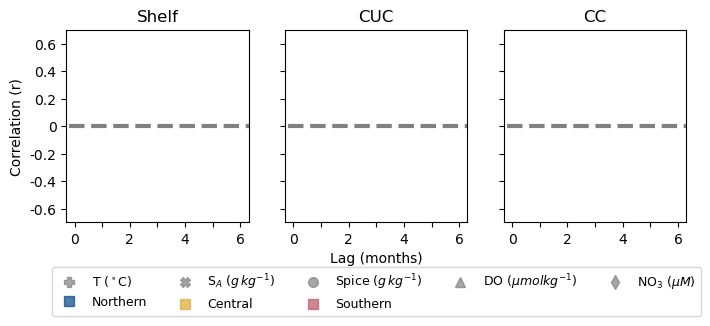

In [21]:
# PDO
indice= pdo
Lindice=Lpdo
p=0.1

fig, axs = plt.subplots(1,3,figsize=[8,2.5])

for ax in axs:
    ax.set_ylim([-0.7,0.7])
    ax.set_xlim([-0.3,6.3])
    ax.plot([-1,7],[0,0],color='grey',ls='dashed',lw=3)
    ax.set_yticks([-0.6,-0.4,-0.2,0,0.2,0.4,0.6])
    ax.set_yticklabels([])
    ax.set_xticks([0,1,2,3,4,5,6])
    ax.set_xticklabels(['0','','2','','4','','6'])
axs[0].set_yticklabels([-0.6,-0.4,-0.2,0,0.2,0.4,0.6])
axs[0].set_ylabel('Correlation (r)')
axs[1].set_xlabel('Lag (months)')
axs[0].set_title('Shelf')
axs[1].set_title('CUC')
axs[2].set_title('CC')

sig_count = 0
obs_used = obs_shelf.copy()
dist_edges = [np.nanmin(obs_used['latitude (degrees_north)'])-0.1,34.45,40.44,np.nanmax(obs_used['latitude (degrees_north)'])+0.1]
n = summary_plot(axs[0], obs_used, indice, Lindice,dist_edges,p=p)
sig_count += n

obs_used = obs_cuc.copy()
dist_edges = [np.nanmin(obs_used['latitude (degrees_north)'])-0.1,34.45,40.44,np.nanmax(obs_used['latitude (degrees_north)'])+0.1]
n = summary_plot(axs[1], obs_used, indice, Lindice,dist_edges,p=p,do_interp=False)
sig_count += n

obs_used = obs_cc.copy()
dist_edges = [np.nanmin(obs_used['latitude (degrees_north)'])-0.1,34.45,40.44,np.nanmax(obs_used['latitude (degrees_north)'])+0.1]
n = summary_plot(axs[2], obs_used, indice, Lindice,dist_edges,p=p)
sig_count += n

print(sig_count/(5*3*3)*100) # percentage of tested relationships that are significant


# # build legend handles    
legend_handles = []
inlegend = ['T ($^\circ$C)', 'Northern', 'S$_A$ ($g \,kg^{-1}$)', 'Central', 'Spice ($g \,kg^{-1}$)','Southern','DO ($\mu mol kg^{-1}$)','NO$_3$ ($\mu M$)',]
colours = ['grey','#004488','grey','#DDAA33','grey','#BB5566','grey','grey']
markers = ['P','s','X','s','o','s','^','d']
for i in range(len(inlegend)):
    legend_handles.append(mlines.Line2D([], [], 
                          marker=markers[i], linestyle='None',markersize=7,
                          markeredgecolor=colours[i], markerfacecolor=colours[i],alpha=0.7,
                          label=inlegend[i]))
# Add a figure-wide legend below the subplots
axs[1].legend(handles=legend_handles, loc='upper center', ncol=5, bbox_to_anchor=(0.5, -0.2), frameon=True,fontsize=9)

# plt.savefig('/ocean/rbeutel/MOAD/analysis-becca/Synthesis/output/enso.png', bbox_inches='tight')

temperature (degC): common depth range 0–60 m
Retained 947 of 999 eligible monthly profiles (94.8%).
salinity (g kg-1): common depth range 0–60 m
Retained 1105 of 1213 eligible monthly profiles (91.1%).
spice: common depth range 0–60 m
Retained 947 of 999 eligible monthly profiles (94.8%).
DO (umol kg-1): common depth range 0–60 m
Retained 824 of 898 eligible monthly profiles (91.8%).
NO3 (uM): common depth range 0–60 m
Retained 498 of 582 eligible monthly profiles (85.6%).
temperature (degC): common depth range 0–140 m
Retained 724 of 819 eligible monthly profiles (88.4%).
salinity (g kg-1): common depth range 0–140 m
Retained 724 of 819 eligible monthly profiles (88.4%).
spice: common depth range 0–140 m
Retained 724 of 819 eligible monthly profiles (88.4%).
DO (umol kg-1): common depth range 0–130 m
Retained 675 of 757 eligible monthly profiles (89.2%).
NO3 (uM): common depth range 0–120 m
Retained 392 of 426 eligible monthly profiles (92.0%).
0.0


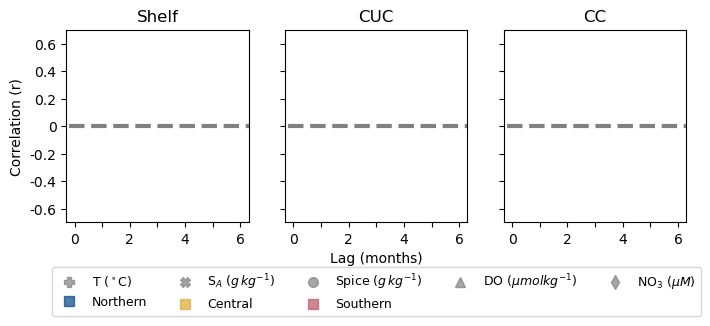

In [22]:
# NPGO
indice= npgo
Lindice = Lnpgo
p=0.2

fig, axs = plt.subplots(1,3,figsize=[8,2.5])

for ax in axs:
    ax.set_ylim([-0.7,0.7])
    ax.set_xlim([-0.3,6.3])
    ax.plot([-1,7],[0,0],color='grey',ls='dashed',lw=3)
    ax.set_yticks([-0.6,-0.4,-0.2,0,0.2,0.4,0.6])
    ax.set_yticklabels([])
    ax.set_xticks([0,1,2,3,4,5,6])
    ax.set_xticklabels(['0','','2','','4','','6'])
axs[0].set_yticklabels([-0.6,-0.4,-0.2,0,0.2,0.4,0.6])
axs[0].set_ylabel('Correlation (r)')
axs[1].set_xlabel('Lag (months)')
axs[0].set_title('Shelf')
axs[1].set_title('CUC')
axs[2].set_title('CC')

sig_count = 0
obs_used = obs_shelf.copy()
dist_edges = [np.nanmin(obs_used['latitude (degrees_north)'])-0.1,34.45,40.44,np.nanmax(obs_used['latitude (degrees_north)'])+0.1]
n = summary_plot(axs[0], obs_used, indice, Lindice,dist_edges,p=p)
sig_count += n

obs_used = obs_cuc.copy()
dist_edges = [np.nanmin(obs_used['latitude (degrees_north)'])-0.1,34.45,40.44,np.nanmax(obs_used['latitude (degrees_north)'])+0.1]
n = summary_plot(axs[1], obs_used, indice, Lindice,dist_edges,p=p,do_interp=False)
sig_count += n

obs_used = obs_cc.copy()
dist_edges = [np.nanmin(obs_used['latitude (degrees_north)'])-0.1,34.45,40.44,np.nanmax(obs_used['latitude (degrees_north)'])+0.1]
n = summary_plot(axs[2], obs_used, indice, Lindice,dist_edges,p=p)
sig_count += n

print(sig_count/(5*3*3)*100) # percentage of tested relationships that are significant


# # build legend handles    
legend_handles = []
inlegend = ['T ($^\circ$C)', 'Northern', 'S$_A$ ($g \,kg^{-1}$)', 'Central', 'Spice ($g \,kg^{-1}$)','Southern','DO ($\mu mol kg^{-1}$)','NO$_3$ ($\mu M$)',]
colours = ['grey','#004488','grey','#DDAA33','grey','#BB5566','grey','grey']
markers = ['P','s','X','s','o','s','^','d']
for i in range(len(inlegend)):
    legend_handles.append(mlines.Line2D([], [], 
                          marker=markers[i], linestyle='None',markersize=7,
                          markeredgecolor=colours[i], markerfacecolor=colours[i],alpha=0.7,
                          label=inlegend[i]))
# Add a figure-wide legend below the subplots
axs[1].legend(handles=legend_handles, loc='upper center', ncol=5, bbox_to_anchor=(0.5, -0.2), frameon=True,fontsize=9)

# plt.savefig('/ocean/rbeutel/MOAD/analysis-becca/Synthesis/output/enso.png', bbox_inches='tight')

temperature (degC): common depth range 0–60 m
Retained 947 of 999 eligible monthly profiles (94.8%).
salinity (g kg-1): common depth range 0–60 m
Retained 1105 of 1213 eligible monthly profiles (91.1%).
spice: common depth range 0–60 m
Retained 947 of 999 eligible monthly profiles (94.8%).
DO (umol kg-1): common depth range 0–60 m
Retained 824 of 898 eligible monthly profiles (91.8%).
NO3 (uM): common depth range 0–60 m
Retained 498 of 582 eligible monthly profiles (85.6%).
temperature (degC): common depth range 0–140 m
Retained 724 of 819 eligible monthly profiles (88.4%).
salinity (g kg-1): common depth range 0–140 m
Retained 724 of 819 eligible monthly profiles (88.4%).
spice: common depth range 0–140 m
Retained 724 of 819 eligible monthly profiles (88.4%).
DO (umol kg-1): common depth range 0–130 m
Retained 675 of 757 eligible monthly profiles (89.2%).
NO3 (uM): common depth range 0–120 m
Retained 392 of 426 eligible monthly profiles (92.0%).
0.0


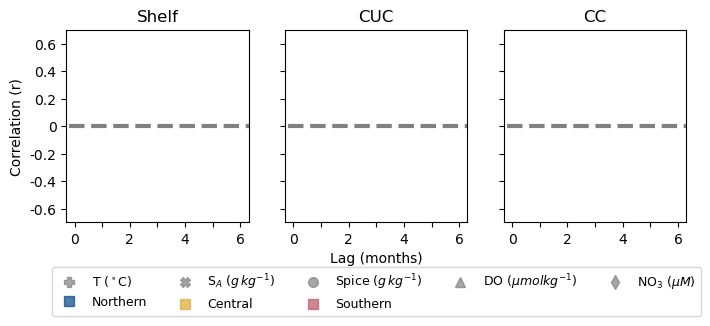

In [23]:
# BI
indice= bi
indices = Lbi
p=0.1

fig, axs = plt.subplots(1,3,figsize=[8,2.5])

for ax in axs:
    ax.set_ylim([-0.7,0.7])
    ax.set_xlim([-0.3,6.3])
    ax.plot([-1,7],[0,0],color='grey',ls='dashed',lw=3)
    ax.set_yticks([-0.6,-0.4,-0.2,0,0.2,0.4,0.6])
    ax.set_yticklabels([])
    ax.set_xticks([0,1,2,3,4,5,6])
    ax.set_xticklabels(['0','','2','','4','','6'])
axs[0].set_yticklabels([-0.6,-0.4,-0.2,0,0.2,0.4,0.6])
axs[0].set_ylabel('Correlation (r)')
axs[1].set_xlabel('Lag (months)')
axs[0].set_title('Shelf')
axs[1].set_title('CUC')
axs[2].set_title('CC')

sig_count = 0
obs_used = obs_shelf.copy()
dist_edges = [np.nanmin(obs_used['latitude (degrees_north)'])-0.1,34.45,40.44,np.nanmax(obs_used['latitude (degrees_north)'])+0.1]
n = summary_plot(axs[0], obs_used, indice, Lindice,dist_edges,p=p)
sig_count += n

obs_used = obs_cuc.copy()
dist_edges = [np.nanmin(obs_used['latitude (degrees_north)'])-0.1,34.45,40.44,np.nanmax(obs_used['latitude (degrees_north)'])+0.1]
n = summary_plot(axs[1], obs_used, indice, Lindice,dist_edges,p=p,do_interp=False)
sig_count += n

obs_used = obs_cc.copy()
dist_edges = [np.nanmin(obs_used['latitude (degrees_north)'])-0.1,34.45,40.44,np.nanmax(obs_used['latitude (degrees_north)'])+0.1]
n = summary_plot(axs[2], obs_used, indice, Lindice,dist_edges,p=p)
sig_count += n

print(sig_count/(5*3*3)*100) # percentage of tested relationships that are significant

# # build legend handles    
legend_handles = []
inlegend = ['T ($^\circ$C)', 'Northern', 'S$_A$ ($g \,kg^{-1}$)', 'Central', 'Spice ($g \,kg^{-1}$)','Southern','DO ($\mu mol kg^{-1}$)','NO$_3$ ($\mu M$)',]
colours = ['grey','#004488','grey','#DDAA33','grey','#BB5566','grey','grey']
markers = ['P','s','X','s','o','s','^','d']
for i in range(len(inlegend)):
    legend_handles.append(mlines.Line2D([], [], 
                          marker=markers[i], linestyle='None',markersize=7,
                          markeredgecolor=colours[i], markerfacecolor=colours[i],alpha=0.7,
                          label=inlegend[i]))
# Add a figure-wide legend below the subplots
axs[1].legend(handles=legend_handles, loc='upper center', ncol=5, bbox_to_anchor=(0.5, -0.2), frameon=True,fontsize=9)

# plt.savefig('/ocean/rbeutel/MOAD/analysis-becca/Synthesis/output/enso.png', bbox_inches='tight')

temperature (degC): common depth range 10–90 m
Retained 440 of 498 eligible monthly profiles (88.4%).
salinity (g kg-1): common depth range 10–90 m
Retained 643 of 764 eligible monthly profiles (84.2%).
spice: common depth range 10–90 m
Retained 440 of 498 eligible monthly profiles (88.4%).
DO (umol kg-1): common depth range 10–90 m
Retained 374 of 435 eligible monthly profiles (86.0%).
NO3 (uM): common depth range 10–90 m
Retained 182 of 205 eligible monthly profiles (88.8%).
temperature (degC): common depth range 10–100 m
Retained 241 of 251 eligible monthly profiles (96.0%).
salinity (g kg-1): common depth range 10–100 m
Retained 241 of 251 eligible monthly profiles (96.0%).
spice: common depth range 10–100 m
Retained 241 of 251 eligible monthly profiles (96.0%).
DO (umol kg-1): common depth range 0–100 m
Retained 201 of 223 eligible monthly profiles (90.1%).
NO3 (uM): common depth range 0–100 m
Retained 121 of 136 eligible monthly profiles (89.0%).
6.666666666666667


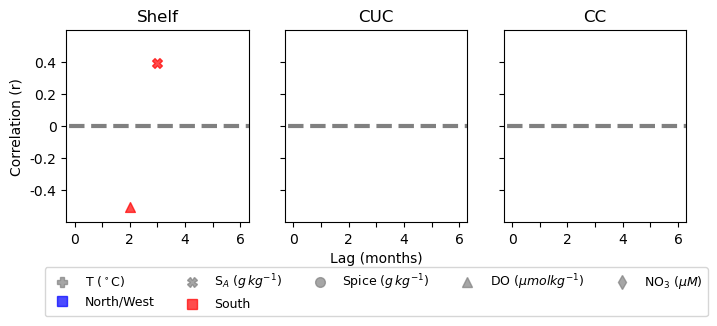

In [24]:
base_period = (1991, 2020)
p=0.1
n=0

num_obs = 50
vars = ['temperature (degC)', 'salinity (g kg-1)','spice','DO (umol kg-1)','NO3 (uM)']
varmark = ['P','X','o','^','d']

dist_edges = [np.min(obs_cc.dist),0,800]

fig, axs = plt.subplots(1,3,figsize=[8,2.5])

for ax in axs:
    ax.set_ylim([-0.6,0.6])
    ax.set_xlim([-0.3,6.3])
    ax.plot([-1,7],[0,0],color='grey',ls='dashed',lw=3)
    ax.set_yticks([-0.4,-0.2,0,0.2,0.4])
    ax.set_yticklabels([])
    ax.set_xticks([0,1,2,3,4,5,6])
    ax.set_xticklabels(['0','','2','','4','','6'])
axs[0].set_yticklabels([-0.4,-0.2,0,0.2,0.4])
axs[0].set_ylabel('Correlation (r)')
axs[1].set_xlabel('Lag (months)')
axs[0].set_title('Shelf')
axs[1].set_title('CUC')
axs[2].set_title('CC')

obs_used = obs_shelf.copy()
ax=axs[0]
for i in range(len(vars)):
    start_yr = int(np.nanmin(obs_used.year[~np.isnan(obs_used[vars[i]])]))
    end_yr   = int(np.nanmax(obs_used.year[~np.isnan(obs_used[vars[i]])]))

    anom_array, t_month = contour_prep_dist_monthly(
        obs_used, start_yr, end_yr, dist_edges,
        vars[i], base_period=base_period, min_samples_per_cell=3,usedist=True
    )
    time = decimal_year_monthstart_to_datetime(t_month)

    L = ACF_lag(anom_array[1],time)
    best = find_best_lag_dof(add_running_mean_12m(anom_array[1],time), t_month, bi,L,Lbi, max_lag_months=6)
    if best['pvalue'] <= p and best['n'] >num_obs:
        ax.scatter(best['best_lag_months'],best['r'],marker=varmark[i],s=50,c='r',alpha=0.7)
        n+=1
    L = ACF_lag(anom_array[0],time)
    best = find_best_lag_dof(add_running_mean_12m(anom_array[0],time), t_month, bi,L,Lbi, max_lag_months=6)
    if best['pvalue'] <= p and best['n'] >num_obs:
        ax.scatter(best['best_lag_months'],best['r'],marker=varmark[i],s=50,c='b',alpha=0.7)
        n+=1

obs_used = obs_cuc.copy()
ax=axs[1]
for i in range(len(vars)):
    start_yr = int(np.nanmin(obs_used.year[~np.isnan(obs_used[vars[i]])]))
    end_yr   = int(np.nanmax(obs_used.year[~np.isnan(obs_used[vars[i]])]))

    anom_array, t_month = contour_prep_dist_monthly(
        obs_used, start_yr, end_yr, dist_edges,
        vars[i], base_period=base_period, min_samples_per_cell=3,usedist=True,do_interp=False
    )
    time = decimal_year_monthstart_to_datetime(t_month)

    L = ACF_lag(anom_array[1],time)
    best = find_best_lag_dof(add_running_mean_12m(anom_array[1],time), t_month, bi,L,Lbi, max_lag_months=6)
    if best['pvalue'] <= p and best['n'] >num_obs:
        ax.scatter(best['best_lag_months'],best['r'],marker=varmark[i],s=50,c='r',alpha=0.7)
        n+=1
    L = ACF_lag(anom_array[0],time)
    best = find_best_lag_dof(add_running_mean_12m(anom_array[0],time), t_month, bi,L,Lbi, max_lag_months=6)
    if best['pvalue'] <= p and best['n'] >num_obs:
        ax.scatter(best['best_lag_months'],best['r'],marker=varmark[i],s=50,c='b',alpha=0.7)
        n+=1

obs_used = obs_cc.copy()
ax=axs[2]
for i in range(len(vars)):
    start_yr = int(np.nanmin(obs_used.year[~np.isnan(obs_used[vars[i]])]))
    end_yr   = int(np.nanmax(obs_used.year[~np.isnan(obs_used[vars[i]])]))

    anom_array, t_month = contour_prep_dist_monthly(
        obs_used, start_yr, end_yr, dist_edges,
        vars[i], base_period=base_period, min_samples_per_cell=3,usedist=True
    )
    time = decimal_year_monthstart_to_datetime(t_month)

    L = ACF_lag(anom_array[1],time)
    best = find_best_lag_dof(add_running_mean_12m(anom_array[1],time), t_month, bi,L,Lbi, max_lag_months=6)
    if best['pvalue'] <= p and best['n'] >num_obs:
        ax.scatter(best['best_lag_months'],best['r'],marker=varmark[i],s=50,c='r',alpha=0.7)
        n+=1
    L = ACF_lag(anom_array[0],time)
    best = find_best_lag_dof(add_running_mean_12m(anom_array[0],time), t_month, bi,L,Lbi, max_lag_months=6)
    if best['pvalue'] <= p and best['n'] >num_obs:
        ax.scatter(best['best_lag_months'],best['r'],marker=varmark[i],s=50,c='b',alpha=0.7)
        n+=1

print(n/(2*3*5)*100)

# # build legend handles    
legend_handles = []
inlegend = ['T ($^\circ$C)', 'North/West', 'S$_A$ ($g \,kg^{-1}$)', 'South', 'Spice ($g \,kg^{-1}$)','DO ($\mu mol kg^{-1}$)','NO$_3$ ($\mu M$)',]
colours = ['grey','b','grey','r','grey','grey','grey']
markers = ['P','s','X','s','o','^','d']
for i in range(len(inlegend)):
    legend_handles.append(mlines.Line2D([], [], 
                          marker=markers[i], linestyle='None',markersize=7,
                          markeredgecolor=colours[i], markerfacecolor=colours[i],alpha=0.7,
                          label=inlegend[i]))
# Add a figure-wide legend below the subplots
axs[1].legend(handles=legend_handles, loc='upper center', ncol=5, bbox_to_anchor=(0.5, -0.2), frameon=True,fontsize=9)

# plt.savefig('/ocean/rbeutel/MOAD/analysis-becca/Synthesis/output/BI_CCsplit.png', bbox_inches='tight')